# Laboratorul nr. 2

## Student: Trandafir Florin-Daniel IASD 2601

In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path("Orange_Telecom_Churn_Data.csv")
data = pd.read_csv(DATA_PATH)
print(f"Date încărcate: {data.shape[0]} clienți, {data.shape[1]} coloane")
print(f"Valori lipsă: {int(data.isna().sum().sum())}")


Date încărcate: 5000 clienți, 21 coloane
Valori lipsă: 0


### Exercițiul 1: Ingineria caracteristicilor și eliminarea coloanelor irelevante

In [15]:
coloane_eliminate = ["state", "area_code", "phone_number"]
coloane_categoriale_ramase = ["intl_plan", "voice_mail_plan"]
coloane_analizate = coloane_eliminate + coloane_categoriale_ramase

cardinalitate = pd.DataFrame({
    "coloană": coloane_analizate,
    "valori_unice": [data[c].nunique() for c in coloane_analizate],
    "folosită_în_model": [c not in coloane_eliminate for c in coloane_analizate],
})
print(cardinalitate.to_string(index=False))
print(f"Dimensiunea One-Hot doar pentru phone_number: {data['phone_number'].nunique()} coloane")


        coloană  valori_unice  folosită_în_model
          state            51              False
      area_code             3              False
   phone_number          5000              False
      intl_plan             2               True
voice_mail_plan             2               True
Dimensiunea One-Hot doar pentru phone_number: 5000 coloane


Un număr de telefon este un identificator, nu o măsură a comportamentului. Pentru 5.000 de numere distincte,
codificarea One-Hot adaugă 5.000 de coordonate. Reprezentarea densă float64 ar ocupa aproximativ
5.000 × 5.000 × 8 = 200 MB numai pentru această coloană. O reprezentare rară reduce memoria,
dar nu face distanțele mai utile: între doi identificatori diferiți, distanța euclidiană pe această
codificare este mereu √2. Modelul poate astfel favoriza potriviri accidentale și memorarea exemplelor,
fără un semnal care să se generalizeze. Eliminăm state, area_code și phone_number conform laboratorului.

### Exercițiul 2: Impactul scalării datelor asupra distanței euclidiene

In [16]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

clienti = np.array([[1.0, 0.0], [250.0, 100.0]])
cu_outlier = np.vstack([clienti, [1000.0, 1000.0]])

for nume, model in [
    ("Fără scalare", None),
    ("MinMaxScaler", MinMaxScaler()),
    ("StandardScaler", StandardScaler()),
]:
    transformed = clienti if model is None else model.fit_transform(clienti)
    diferente = np.abs(transformed[0] - transformed[1])
    print(f"{nume}: contribuții={diferente.round(3)}, distanță={np.linalg.norm(diferente):.3f}")

for nume, model in [
    ("MinMaxScaler cu outlier", MinMaxScaler()),
    ("StandardScaler cu outlier", StandardScaler()),
]:
    transformed = model.fit_transform(cu_outlier)
    diferente = np.abs(transformed[0] - transformed[1])
    print(f"{nume}: contribuții={diferente.round(3)}, distanță={np.linalg.norm(diferente):.3f}")


Fără scalare: contribuții=[249. 100.], distanță=268.330
MinMaxScaler: contribuții=[1. 1.], distanță=1.414
StandardScaler: contribuții=[2. 2.], distanță=2.828
MinMaxScaler cu outlier: contribuții=[0.249 0.1  ], distanță=0.269
StandardScaler cu outlier: contribuții=[0.586 0.222], distanță=0.627


Fără scalare, diferența de 249 la account_length domină diferența de 100 la total_day_charge
în suma pătratelor din distanța euclidiană. Exemplul folosește intenționat doar două observații
pentru a arăta contribuțiile; în modelul real, scalerul se potrivește numai pe datele de antrenare.
Un outlier extinde intervalul MinMax și modifică media și deviația standard pentru StandardScaler.
Ambele metode comprimă distanțele dintre observațiile obișnuite în acest exemplu.

### Exercițiul 3: Optimizare hardware cu Intel® Extension for Scikit-learn

Extensia Intel poate accelera KNN prin implementări optimizate; câștigul depinde de date și de hardware. Comparăm timpul de antrenare pe aceleași 100.000 de exemple.

In [17]:
import subprocess
import sys
from timeit import timeit
from sklearn.neighbors import KNeighborsClassifier

rng = np.random.default_rng(42)
X = rng.random((100_000, 10))
y = rng.integers(0, 2, 100_000)
timp_sklearn = timeit(lambda: KNeighborsClassifier(n_neighbors=5).fit(X, y), number=1)
print(f"scikit-learn: {timp_sklearn:.3f} s")

# Proces separat: patch-ul Intel nu schimbă restul notebookului.
script_intel = """
import numpy as np
from timeit import timeit
from sklearnex import patch_sklearn
patch_sklearn()
from sklearn.neighbors import KNeighborsClassifier
rng = np.random.default_rng(42)
X = rng.random((100_000, 10))
y = rng.integers(0, 2, 100_000)
print(timeit(lambda: KNeighborsClassifier(n_neighbors=5).fit(X, y), number=1))
"""
try:
    rezultat = subprocess.run(
        [sys.executable, "-c", script_intel],
        capture_output=True, text=True, check=True, timeout=120,
    )
    print(f"Intel sklearnex: {float(rezultat.stdout.splitlines()[-1]):.3f} s")
except (OSError, subprocess.CalledProcessError, subprocess.TimeoutExpired,
        ValueError, IndexError):
    print("Intel sklearnex: indisponibil (neinstalat sau incompatibil cu acest mediu).")


scikit-learn: 0.109 s
Intel sklearnex: indisponibil (neinstalat sau incompatibil cu acest mediu).


### Exercițiul 4: Analiza matematică a metricilor de distanță (Minkowski, Manhattan, Euclidiană)

p=1: distanța=7.000
p=2: distanța=5.000
p=inf: distanța=4.000


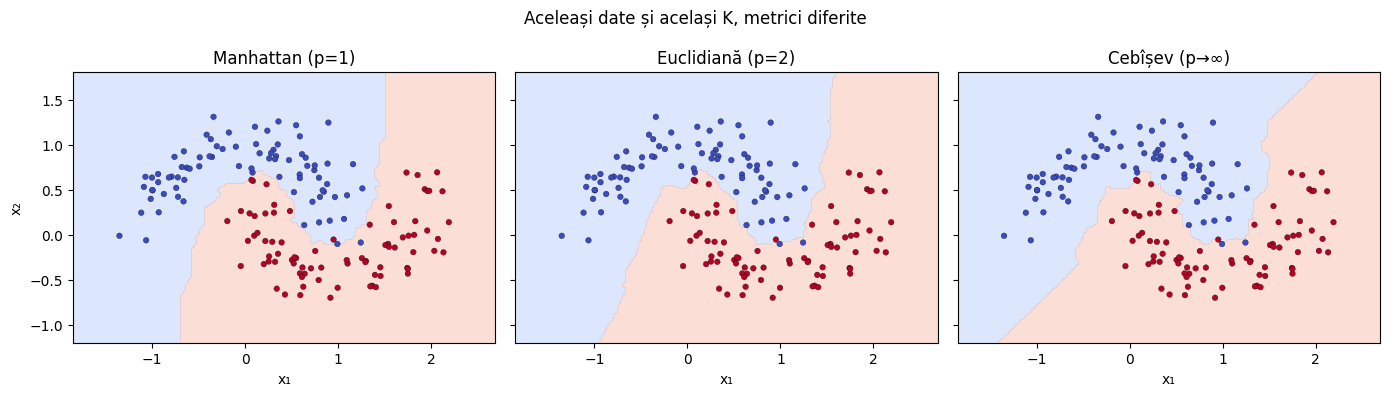

In [18]:
from sklearn.datasets import make_moons

def minkowski_distance(x, y, p):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if x.shape != y.shape:
        raise ValueError("Punctele trebuie să aibă aceeași formă.")
    if p < 1:
        raise ValueError("p trebuie să fie cel puțin 1.")
    diferente = np.abs(x - y)
    if np.isinf(p):
        return float(np.max(diferente))
    return float(np.linalg.norm(diferente.ravel(), ord=p))

punct_a = np.array([0.0, 0.0])
punct_b = np.array([3.0, 4.0])
for p in [1, 2, np.inf]:
    print(f"p={p}: distanța={minkowski_distance(punct_a, punct_b, p):.3f}")

X_2d, y_2d = make_moons(n_samples=160, noise=0.19, random_state=42)
xx, yy = np.meshgrid(
    np.linspace(X_2d[:, 0].min() - 0.5, X_2d[:, 0].max() + 0.5, 160),
    np.linspace(X_2d[:, 1].min() - 0.5, X_2d[:, 1].max() + 0.5, 160),
)
grila = np.c_[xx.ravel(), yy.ravel()]
fig, axe = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)
for ax, (titlu, metrica) in zip(axe, [
    ("Manhattan (p=1)", {"metric": "minkowski", "p": 1}),
    ("Euclidiană (p=2)", {"metric": "minkowski", "p": 2}),
    ("Cebîșev (p→∞)", {"metric": "chebyshev"}),
]):
    model = KNeighborsClassifier(n_neighbors=5, **metrica).fit(X_2d, y_2d)
    regiuni = model.predict(grila).reshape(xx.shape)
    ax.contourf(xx, yy, regiuni, levels=[-0.5, 0.5, 1.5], alpha=0.3, cmap="coolwarm")
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=y_2d, s=17, cmap="coolwarm", edgecolor="k", linewidth=0.2)
    ax.set_title(titlu)
    ax.set_xlabel("x₁")
axe[0].set_ylabel("x₂")
fig.suptitle("Aceleași date și același K, metrici diferite")
fig.tight_layout()
plt.show()


Minkowski cu p=1 însumează diferențele absolute, cu p=2 dă distanța euclidiană,
iar limita p→∞ este cea mai mare diferență pe o coordonată. Când metrica se schimbă,
se pot schimba vecinii cei mai apropiați și, prin urmare, frontiera de decizie.

### Exercițiul 5: Paradoxul preciziei de 100% la K=3 pe eșantionul de antrenare

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

X_all = data.drop(columns=["state", "area_code", "phone_number", "churned"]).copy()
for coloana in ["intl_plan", "voice_mail_plan"]:
    X_all[coloana] = X_all[coloana].map({"no": 0, "yes": 1}).astype(int)
y_all = data["churned"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=42
)
assert X_train.select_dtypes(exclude="number").empty
assert set(X_train.index).isdisjoint(X_test.index)

def knn_pipeline(k, weights="uniform", p=2):
    return Pipeline([
        ("scale", MinMaxScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k, weights=weights, p=p)),
    ])

for eticheta, model in [
    ("K=1, uniform", knn_pipeline(1)),
    ("K=3, distance", knn_pipeline(3, weights="distance")),
]:
    model.fit(X_train, y_train)
    print(f"{eticheta}: train={accuracy_score(y_train, model.predict(X_train)):.3f}, "
          f"test={accuracy_score(y_test, model.predict(X_test)):.3f}")
print(f"Împărțire: {len(X_train)} train, {len(X_test)} test; "
      f"churn train={y_train.mean():.3f}, churn test={y_test.mean():.3f}")


K=1, uniform: train=1.000, test=0.878
K=3, distance: train=1.000, test=0.894
Împărțire: 4000 train, 1000 test; churn train=0.141, churn test=0.141


La predicția pe datele de antrenare, punctul xᵢ este propriul său vecin la distanța zero.
Cu K=1, acesta își votează propria etichetă. Cu weights='distance', vecinul de distanță zero
domină votul chiar și pentru K=3. Acuratețea de 100% măsoară astfel memorarea exemplelor,
nu capacitatea de a prezice clienți noi. Scorul relevant este cel pe setul de test separat.

### Exercițiul 6: Implementarea propriului algoritm KNN de la zero

In [20]:
class CustomKNN:
    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        if self.X_train.ndim != 2 or self.y_train.ndim != 1:
            raise ValueError("X trebuie să fie 2D și y trebuie să fie 1D.")
        if len(self.X_train) != len(self.y_train) or len(self.y_train) == 0:
            raise ValueError("X și y trebuie să aibă același număr nenul de rânduri.")
        self.classes_, self.codes_ = np.unique(self.y_train, return_inverse=True)
        return self

    def predict(self, X_test, k=3):
        X_test = np.asarray(X_test, dtype=float)
        if X_test.ndim != 2 or X_test.shape[1] != self.X_train.shape[1]:
            raise ValueError("X_test are o formă incompatibilă.")
        if not 1 <= k <= len(self.X_train):
            raise ValueError("k trebuie să fie între 1 și numărul exemplelor de antrenare.")
        rezultate = []
        patrate_train = np.sum(self.X_train ** 2, axis=1)
        for inceput in range(0, len(X_test), 128):
            lot = X_test[inceput:inceput + 128]
            distante2 = np.maximum(
                np.sum(lot ** 2, axis=1)[:, None] + patrate_train[None, :]
                - 2 * lot @ self.X_train.T, 0.0
            )
            vecini = np.argpartition(distante2, kth=k - 1, axis=1)[:, :k]
            voturi = np.zeros((len(lot), len(self.classes_)), dtype=int)
            np.add.at(voturi, (np.arange(len(lot))[:, None], self.codes_[vecini]), 1)
            rezultate.append(self.classes_[np.argmax(voturi, axis=1)])
        return np.concatenate(rezultate)

scaler_custom = MinMaxScaler().fit(X_train.iloc[:300])
X_custom_train = scaler_custom.transform(X_train.iloc[:300])
X_custom_test = scaler_custom.transform(X_test.iloc[:80])
y_custom_train = y_train.iloc[:300].to_numpy()
y_custom_test = y_test.iloc[:80].to_numpy()

custom = CustomKNN().fit(X_custom_train, y_custom_train)
predictii_custom = custom.predict(X_custom_test, k=5)
referinta = KNeighborsClassifier(n_neighbors=5).fit(X_custom_train, y_custom_train)
predictii_referinta = referinta.predict(X_custom_test)
print(f"CustomKNN: acuratețe pe 80 clienți noi = {accuracy_score(y_custom_test, predictii_custom):.3f}")
print(f"Concordanță cu scikit-learn = {np.mean(predictii_custom == predictii_referinta):.3f}")


CustomKNN: acuratețe pe 80 clienți noi = 0.887
Concordanță cu scikit-learn = 1.000


Implementarea folosește distanța euclidiană la pătrat: ordinea vecinilor este aceeași,
iar rădăcina pătrată nu mai trebuie calculată. Procesează interogările în loturi NumPy,
selectează K vecini cu argpartition și votează majoritar. La egalitate, alege clasa
cu valoarea mai mică, deoarece np.unique ordonează clasele.

### Exercițiul 7: Validare încrucișată (Cross-Validation) pentru alegerea K-ului optim

 K  acuratețe_medie  deviație_standard
 1           0.8778             0.0057
 2           0.8918             0.0054
 3           0.9062             0.0041
 4           0.8968             0.0073
 5           0.9050             0.0074
 6           0.8948             0.0056
 7           0.9038             0.0060
 8           0.8920             0.0032
 9           0.9000             0.0042
10           0.8918             0.0036
11           0.9005             0.0042
12           0.8880             0.0041
13           0.8962             0.0035
14           0.8882             0.0041
15           0.8938             0.0025
16           0.8885             0.0033
17           0.8908             0.0023
18           0.8875             0.0026
19           0.8915             0.0036
20           0.8853             0.0046
21           0.8882             0.0050
22           0.8848             0.0040
23           0.8880             0.0042
24           0.8842             0.0052
25           0.8868      

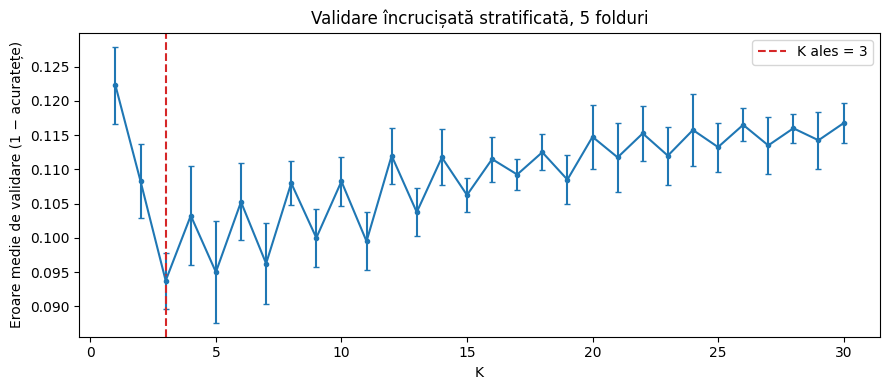

In [21]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
randuri_cv = []
for k in range(1, 31):
    scoruri = cross_val_score(
        knn_pipeline(k), X_train, y_train, cv=cv, scoring="accuracy", n_jobs=1
    )
    randuri_cv.append((k, scoruri.mean(), scoruri.std()))
rezultate_cv = pd.DataFrame(randuri_cv, columns=["K", "acuratețe_medie", "deviație_standard"])
best_k = int(rezultate_cv.sort_values(
    ["acuratețe_medie", "K"], ascending=[False, True]
).iloc[0]["K"])
print(rezultate_cv.round(4).to_string(index=False))
print(f"K optim după acuratețea medie pe cele 5 folduri: {best_k}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(
    rezultate_cv["K"], 1 - rezultate_cv["acuratețe_medie"],
    yerr=rezultate_cv["deviație_standard"], marker="o", markersize=3, capsize=2
)
ax.axvline(best_k, color="tab:red", linestyle="--", label=f"K ales = {best_k}")
ax.set(xlabel="K", ylabel="Eroare medie de validare (1 − acuratețe)",
       title="Validare încrucișată stratificată, 5 folduri")
ax.legend()
fig.tight_layout()
plt.show()


Fiecare fold reantrenează scalerul pe propriul său subset de antrenare.
Alegerea lui K folosește numai cei 4.000 de clienți din setul de antrenare.
La scoruri egale, este ales cel mai mic K. Setul de test rămâne rezervat evaluării finale.

### Exercițiul 8: Lucrul cu clase dezechilibrate (Class Imbalance)

In [22]:
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score, f1_score, classification_report
)

model_ales = knn_pipeline(best_k).fit(X_train, y_train)
y_pred = model_ales.predict(X_test)
matrice = confusion_matrix(y_test, y_pred, labels=[0, 1])
evaluare = pd.DataFrame([{
    "acuratețe": accuracy_score(y_test, y_pred),
    "precision_churn": precision_score(y_test, y_pred, zero_division=0),
    "recall_churn": recall_score(y_test, y_pred, zero_division=0),
    "F1_churn": f1_score(y_test, y_pred, zero_division=0),
    "acuratețe_baseline_fără_churn": 1 - y_test.mean(),
}])
print("Matrice de confuzie (rânduri=real, coloane=prezis; ordine: 0, 1):")
print(matrice)
print(evaluare.round(4).to_string(index=False))
print(classification_report(y_test, y_pred, target_names=["fără churn", "churn"], zero_division=0))


Matrice de confuzie (rânduri=real, coloane=prezis; ordine: 0, 1):
[[834  25]
 [ 81  60]]
 acuratețe  precision_churn  recall_churn  F1_churn  acuratețe_baseline_fără_churn
     0.894           0.7059        0.4255     0.531                          0.859
              precision    recall  f1-score   support

  fără churn       0.91      0.97      0.94       859
       churn       0.71      0.43      0.53       141

    accuracy                           0.89      1000
   macro avg       0.81      0.70      0.74      1000
weighted avg       0.88      0.89      0.88      1000



Clasa fără churn reprezintă majoritatea. Un model care prezice mereu această clasă
obține o acuratețe mare, dar recall=0 pentru clienții care pleacă. Matricea de confuzie,
precision, recall și F1 pentru churn arată câți clienți pierduți sunt identificați și
câte alarme false produce modelul.

### Exercițiul 9: Impactul ponderilor distanței (weights='distance') versus ponderi uniforme

In [23]:
# Patru exemple normale din clasa 0 și un exemplu din clasa 1.
X_zgomot_curat = np.array([
    [0.20, 0.00], [-0.20, 0.00], [0.00, 0.20], [0.00, -0.20], [2.00, 2.00]
])
y_zgomot = np.array([0, 0, 0, 0, 1])
X_zgomot_mutat = X_zgomot_curat.copy()
X_zgomot_mutat[-1] = [0.005, 0.0]  # observație anormală foarte aproape de interogare
intrebare = np.array([[0.0, 0.0]])

randuri_ponderi = []
for stare, puncte in [("fără zgomot", X_zgomot_curat), ("cu punct mutat", X_zgomot_mutat)]:
    for ponderi in ["uniform", "distance"]:
        model = KNeighborsClassifier(n_neighbors=5, weights=ponderi).fit(puncte, y_zgomot)
        randuri_ponderi.append({
            "date": stare,
            "ponderi": ponderi,
            "predicție": int(model.predict(intrebare)[0]),
            "probabilitate_clasa_1": model.predict_proba(intrebare)[0, 1],
        })
print(pd.DataFrame(randuri_ponderi).round(4).to_string(index=False))


          date  ponderi  predicție  probabilitate_clasa_1
   fără zgomot  uniform          0                 0.2000
   fără zgomot distance          0                 0.0174
cu punct mutat  uniform          0                 0.2000
cu punct mutat distance          1                 0.9091


În experimentul controlat, punctul anormal al clasei 1 este mutat foarte aproape de
interogare. Votul uniform rămâne 4 la 1 pentru clasa 0; votul ponderat poate fi dominat
de singurul punct extrem de apropiat. Aceasta arată o vulnerabilitate la zgomotul local.
Nu există o variantă universal mai vulnerabilă: efectul depinde de locul și eticheta
observațiilor perturbate.

### Exercițiul 10: Blestemul dimensionalității (Curse of Dimensionality)

 caracteristici_zgomot  acuratețe  F1_churn
                     0      0.894    0.5310
                    10      0.851    0.2199
                    30      0.842    0.2100
                    80      0.843    0.1229


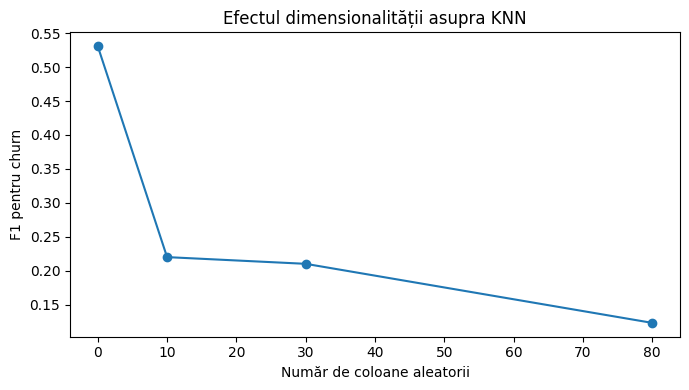

In [24]:
generator_zgomot = np.random.default_rng(42)
niveluri = [0, 10, 30, 80]
randuri_dimensiuni = []
for nr_zgomot in niveluri:
    X_tr_ext = X_train.copy()
    X_te_ext = X_test.copy()
    if nr_zgomot:
        zgomot_train = generator_zgomot.random((len(X_train), nr_zgomot))
        zgomot_test = generator_zgomot.random((len(X_test), nr_zgomot))
        nume = [f"zgomot_{i}" for i in range(nr_zgomot)]
        X_tr_ext = pd.concat(
            [X_tr_ext, pd.DataFrame(zgomot_train, index=X_train.index, columns=nume)], axis=1
        )
        X_te_ext = pd.concat(
            [X_te_ext, pd.DataFrame(zgomot_test, index=X_test.index, columns=nume)], axis=1
        )
    model = knn_pipeline(best_k).fit(X_tr_ext, y_train)
    predictii = model.predict(X_te_ext)
    randuri_dimensiuni.append({
        "caracteristici_zgomot": nr_zgomot,
        "acuratețe": accuracy_score(y_test, predictii),
        "F1_churn": f1_score(y_test, predictii, zero_division=0),
    })
rezultate_dim = pd.DataFrame(randuri_dimensiuni)
print(rezultate_dim.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(rezultate_dim["caracteristici_zgomot"], rezultate_dim["F1_churn"], marker="o")
ax.set(xlabel="Număr de coloane aleatorii", ylabel="F1 pentru churn",
       title="Efectul dimensionalității asupra KNN")
fig.tight_layout()
plt.show()


Coloanele adăugate sunt zgomot uniform independent de etichetă. În distanța euclidiană,
fiecare coordonată suplimentară contribuie la sumă; cu multe coordonate irelevante,
diferențele utile dintre clienți devin relativ mai greu de observat. Măsurăm efectul
pe exact aceeași împărțire train/test și păstrăm K constant.

### Exercițiul 11: KNN pentru regresie versus clasificare

 K    MSE
 1 1.1926
 3 1.0103
 5 0.6411
 9 0.6464
15 0.8709
30 1.1297


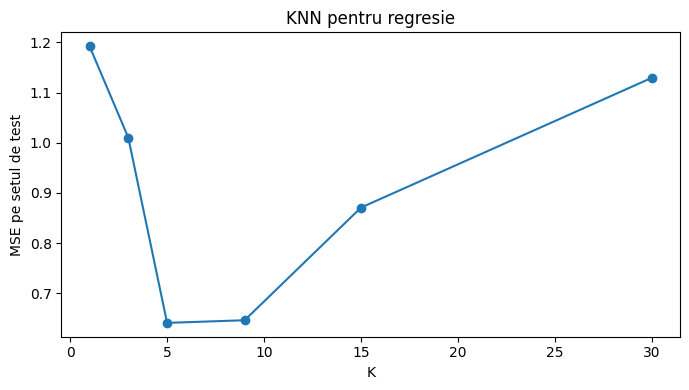

In [25]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error

# Tariful pe minut face această țintă aproape deterministă: exercițiu ilustrativ.
X_reg = data[["total_day_minutes", "total_day_calls"]]
y_reg = data["total_day_charge"]
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)
randuri_regresie = []
for k in [1, 3, 5, 9, 15, 30]:
    model = Pipeline([
        ("scale", MinMaxScaler()),
        ("knn", KNeighborsRegressor(n_neighbors=k)),
    ]).fit(X_reg_train, y_reg_train)
    mse = mean_squared_error(y_reg_test, model.predict(X_reg_test))
    randuri_regresie.append({"K": k, "MSE": mse})
rezultate_regresie = pd.DataFrame(randuri_regresie)
print(rezultate_regresie.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(rezultate_regresie["K"], rezultate_regresie["MSE"], marker="o")
ax.set(xlabel="K", ylabel="MSE pe setul de test", title="KNN pentru regresie")
fig.tight_layout()
plt.show()


Clasificatorul votează pentru o clasă, iar regresorul mediază valorile numerice ale vecinilor.
Aici total_day_charge este calculat aproape direct din total_day_minutes; MSE-ul rezultat
arată mai ales interpolarea unui tarif, nu o problemă independentă de predicție.

### Exercițiul 12: Conducte de învățare automată cu Pipeline și GridSearchCV

In [26]:
from sklearn.model_selection import GridSearchCV
from sklearn.feature_selection import SelectKBest, f_classif

conducta = Pipeline([
    ("scale", MinMaxScaler()),
    ("select", "passthrough"),
    ("knn", KNeighborsClassifier()),
])
setari_comune = {
    "knn__n_neighbors": [3, 5, 7, 9, 11],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}
grila = [
    {"select": ["passthrough"], **setari_comune},
    {"select": [SelectKBest(score_func=f_classif, k=10)], **setari_comune},
]
cautare = GridSearchCV(
    conducta, grila, cv=cv, scoring="f1", n_jobs=1, refit=True, error_score="raise"
)
cautare.fit(X_train, y_train)
pred_test_grid = cautare.predict(X_test)
print("Cei mai buni hiperparametri:", cautare.best_params_)
print(f"F1 mediu în validare: {cautare.best_score_:.4f}")
print(f"Pe test: F1={f1_score(y_test, pred_test_grid):.4f}, "
      f"acuratețe={accuracy_score(y_test, pred_test_grid):.4f}, "
      f"precision={precision_score(y_test, pred_test_grid, zero_division=0):.4f}, "
      f"recall={recall_score(y_test, pred_test_grid, zero_division=0):.4f}")


Cei mai buni hiperparametri: {'knn__n_neighbors': 5, 'knn__p': 2, 'knn__weights': 'uniform', 'select': SelectKBest()}
F1 mediu în validare: 0.6561
Pe test: F1=0.5974, acuratețe=0.9070, precision=0.7667, recall=0.4894


GridSearchCV alege combinația după F1 pentru clasa churn, mai informativ decât acuratețea
când clasele sunt dezechilibrate. Scalerul și selecția caracteristicilor sunt în conductă,
deci sunt ajustate separat în fiecare fold. Setul de test este folosit numai la final.